# INF201 – Deliverable 1: Weather data from Ås

**Authors:** Didrik Wang Berthinsen and Theodor Furuseth

**GitHub repository:** https://github.com/theodorfuruseth-spec/inf201-deliverable-1

## Introduction

In this deliverable we analyse daily weather observations from the weather station in Ås (station ID `SN17850`), run by The Norwegian Meteorological Institute (MET). The data is fetched directly from MET's Frost API ([frost.met.no](https://frost.met.no)) and handled with `pandas`, plotted with `matplotlib`, and the heatwave summary is written to a yml file with `PyYAML`.

The notebook has five parts:

1. Daily mean temperature in 2025, with a plot and a summary table
2. Daily precipitation combined with temperature in one plot
3. A comparison of 2025 with the same year 100 years earlier (1925)
4. A function that counts heatwaves for any station and year
5. A function for the 7-day moving average temperature

The code for requesting data from Frost is based on the Python example from MET on frost.met.no, rewritten for this assignment. The client ID is read from a file in the home folder, outside the repository, and is never part of the code.

Packages needed (install once in a terminal): `pip install requests pandas matplotlib pyyaml`

In [1]:
import os
import re
from pathlib import Path
 
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml
 
 
def load_client_id() -> str:
    """Read the client ID from the environment variable FROST_CLIENT_ID,
    or from the file ~/frost_client_id.txt. The ID is never stored in the repo."""
    from_env = os.environ.get("FROST_CLIENT_ID")
    if from_env:
        return from_env.strip()
    return Path("~/frost_client_id.txt").expanduser().read_text().strip()
 
 
client_id = load_client_id()
ENDPOINT = "https://frost.met.no/observations/v0.jsonld"
STATION = "SN17850"  # Ås

In [2]:
def get_frost(station: str, element: str, start: str, end: str, client_id: str) -> pd.Series:
    """Fetch one element from Frost and return it as a pandas Series indexed by date.
    The end date is not included, as in the Frost API."""
    parameters = {
        "sources": station,
        "elements": element,
        "referencetime": f"{start}/{end}",
    }
    r = requests.get(ENDPOINT, parameters, auth=(client_id, ""))
    if r.status_code == 404:
        raise ValueError(f"No data found for {station}, {element}, {start}/{end}")
    r.raise_for_status()
 
    rows = []
    for item in r.json()["data"]:
        observations = item["observations"]
        # Prefer the midnight-to-midnight series (PT0H), otherwise keep the first one
        chosen = observations[0]
        for obs in observations:
            if obs.get("timeOffset") == "PT0H":
                chosen = obs
                break
        rows.append({"time": item["referenceTime"], "value": chosen["value"]})
    df = pd.DataFrame(rows)
    df["time"] = pd.to_datetime(df["time"]).dt.tz_localize(None)
    df = df.set_index("time")
    df = df[~df.index.duplicated()]
    return df["value"].rename(element)

## Task 1: Temperature

We fetch the daily mean temperature for 2025 and plot it as a line, since temperature changes gradually from day to day.

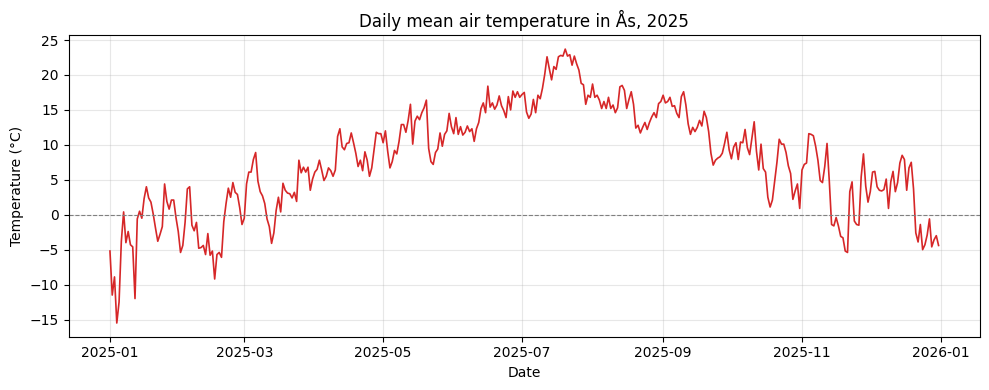

        Temperature 2025 (°C)
Mean                      7.9
Median                    8.3
Min                     -15.5
Max                      23.7


In [3]:
temp = get_frost(STATION, "mean(air_temperature P1D)", "2025-01-01", "2026-01-01", client_id)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(temp.index, temp.values, color="tab:red", linewidth=1.2)
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_title("Daily mean air temperature in Ås, 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

summary_2025 = pd.DataFrame(
    {"Temperature 2025 (°C)": [temp.mean(), temp.median(), temp.min(), temp.max()]},
    index=["Mean", "Median", "Min", "Max"],
).round(1)
print(summary_2025)

### Discussion – Task 1

The plot shows a clear seasonal cycle: cold in winter, rising through spring, warmest in summer and falling in autumn. There is a lot of day-to-day variation on top of this, especially in winter and spring. The table gives the typical temperature (mean and median) and the extremes (min and max), but the annual mean hides the large difference between seasons.

## Task 2: Precipitation

Temperature and precipitation have different units, so they get separate y-axes. Temperature is drawn as a line (continuous value), and precipitation as bars (a daily total).

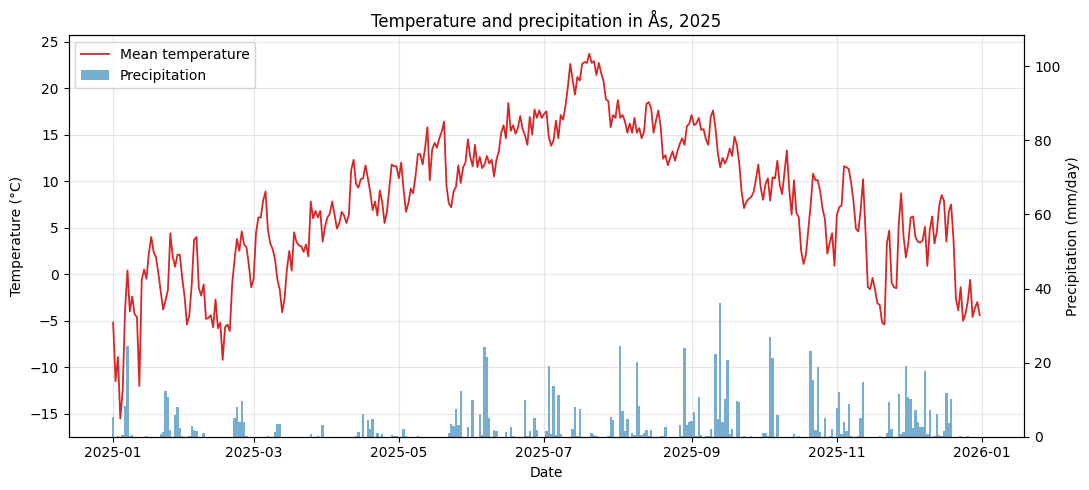

In [4]:
precip = get_frost(STATION, "sum(precipitation_amount P1D)", "2025-01-01", "2026-01-01", client_id)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

# Precipitation as bars (a daily total), on the secondary axis
ax2.bar(precip.index, precip.values, color="tab:blue", alpha=0.6, width=1.0, label="Precipitation")
ax2.set_ylim(0, precip.max() * 3)  # keeps the bars low so they do not hide the temperature line
ax2.set_ylabel("Precipitation (mm/day)")

# Temperature as a line (continuous quantity), drawn on top
ax1.plot(temp.index, temp.values, color="tab:red", linewidth=1.3, label="Mean temperature")
ax1.set_ylabel("Temperature (°C)")
ax1.set_xlabel("Date")
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
ax1.grid(alpha=0.3)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Temperature and precipitation in Ås, 2025")
fig.tight_layout()
plt.show()

### Discussion – Task 2

Precipitation is very uneven: many days have little or none, and a few days have large amounts. We see no simple day-to-day relationship between temperature and precipitation. Showing both in one plot is still useful, since it shows when the weather was warm and dry, and when it was cold or wet.

## Task 3: Historical temperature data (1925 vs 2025)

We fetch the 1925 temperatures and shift the dates forward by 100 years, so both years can be compared on the same x-axis.

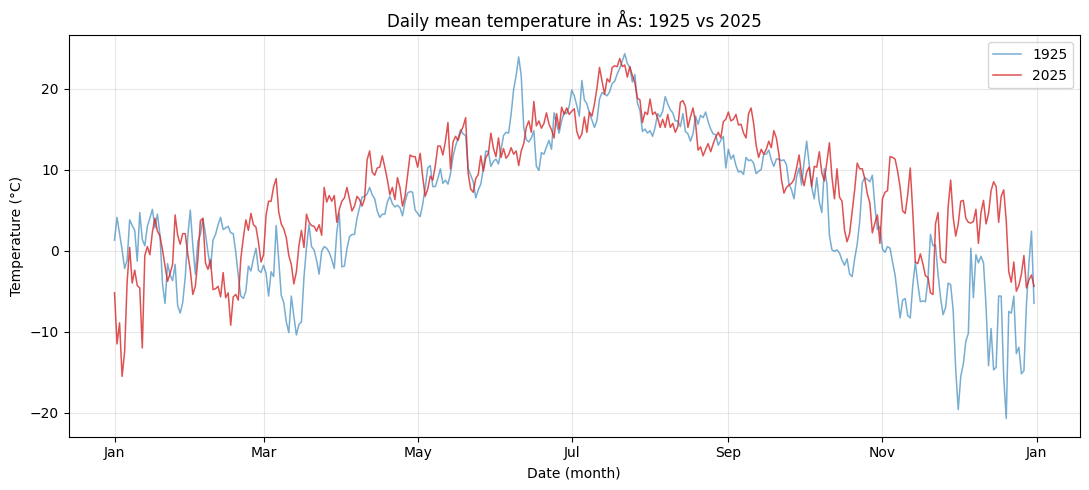

        2025 (°C)  1925 (°C)
Mean          7.9        5.3
Median        8.3        5.3
Min         -15.5      -20.7
Max          23.7       24.3


In [5]:
temp_old = get_frost(STATION, "mean(air_temperature P1D)", "1925-01-01", "1926-01-01", client_id)

# Shift the 1925 dates by 100 years so both years share the same x-axis
temp_old_shifted = temp_old.copy()
temp_old_shifted.index = temp_old.index + pd.DateOffset(years=100)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(temp_old_shifted.index, temp_old_shifted.values, color="tab:blue", alpha=0.6, linewidth=1.1, label="1925")
ax.plot(temp.index, temp.values, color="tab:red", alpha=0.8, linewidth=1.1, label="2025")
ax.set_title("Daily mean temperature in Ås: 1925 vs 2025")
ax.set_xlabel("Date (month)")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

summary_compare = pd.DataFrame(
    {
        "2025 (°C)": [temp.mean(), temp.median(), temp.min(), temp.max()],
        "1925 (°C)": [temp_old.mean(), temp_old.median(), temp_old.min(), temp_old.max()],
    },
    index=["Mean", "Median", "Min", "Max"],
).round(1)
print(summary_compare)

### Discussion – Task 3

Both years follow the same seasonal pattern, but the daily curves differ, since the weather on a given date varies from year to year. The difference in annual mean is shown in the table. Two single years are not enough to draw conclusions about climate change, and the measurements may not be fully comparable after 100 years (instruments, station location, how the daily mean was calculated).

## Task 4: Heatwaves

A heatwave is at least five consecutive days with a maximum temperature of 27 °C or more. The function `count_heatwaves(station, year, client_id)` fetches the daily maximum temperatures, finds streaks of hot days, counts those of at least five days, and writes a summary to a yml file. Missing days are treated as not hot, so they break a streak. The station can be given as an ID or a name.

In [ ]:
def resolve_station(station: str, client_id: str) -> tuple[str, str]:
    """Look up a station by ID (e.g. 'SN17850') or name (e.g. 'Ås') and return (station_id, station_name)."""
    if re.fullmatch(r"SN\d+", station.upper()):
        query = {"ids": station.upper()}
    else:
        query = {"name": station}
    r = requests.get("https://frost.met.no/sources/v0.jsonld", query, auth=(client_id, ""))
    if r.status_code == 404:
        raise ValueError(f"No station found for '{station}'")
    r.raise_for_status()
    source = r.json()["data"][0]
    return source["id"], source["name"].title()
 
 
def count_heatwaves(station: str, year: int, client_id: str, outfile: str = "",
                    min_days: int = 5, threshold: float = 27.0) -> int:
    """Count heatwaves (>= min_days consecutive days with max temperature >= threshold)
    for a station and year. Writes a summary to a yml file and returns the count."""
    station_id, station_name = resolve_station(station, client_id)
    tmax = get_frost(station_id, "max(air_temperature P1D)", f"{year}-01-01", f"{year + 1}-01-01", client_id)
 
    # Make sure every day of the year exists. Missing days become NaN and break a streak.
    tmax = tmax.reindex(pd.date_range(f"{year}-01-01", f"{year}-12-31"))
 
    heatwaves = []
    streak_start = None
    streak_length = 0
    previous_day = None
    for day, value in tmax.items():
        if value >= threshold:  # NaN >= threshold is False
            if streak_length == 0:
                streak_start = day
            streak_length += 1
        else:
            if streak_length >= min_days:
                heatwaves.append(f"{streak_start:%Y-%m-%d} - {previous_day:%Y-%m-%d}")
            streak_length = 0
        previous_day = day
 
    # A heatwave can last until the last day of the year
    if streak_length >= min_days:
        heatwaves.append(f"{streak_start:%Y-%m-%d} - {previous_day:%Y-%m-%d}")
 
    summary = {
        "dates": heatwaves,
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }
    if outfile == "":
        outfile = f"heatwaves_{station_id}_{year}.yml"
    with open(outfile, "w", encoding="utf-8") as f:
        yaml.safe_dump(summary, f)
    return len(heatwaves)
 
 
n = count_heatwaves(STATION, 2025, client_id)
print(f"Heatwaves in Ås 2025: {n}")
print(Path(f"heatwaves_{STATION}_2025.yml").read_text(encoding="utf-8"))

Heatwaves in Ås 2025: 1
dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025

C:\Users\theof\OneDrive - Norwegian University of Life Sciences\INF201\deliverable-1\heatwaves_SN17850_2025.yml


### Discussion – Task 4

The function found one heatwave in Ås in 2025, from 16 to 20 July, lasting exactly the minimum of five days. A limitation is that a missing day inside a heatwave would split it in two.

## Task 5: Moving average

The function `moving_average` uses a centered 7-day window. The first and last three days have no value, since they lack neighbours. Daily values are shown as points and the average as a line.

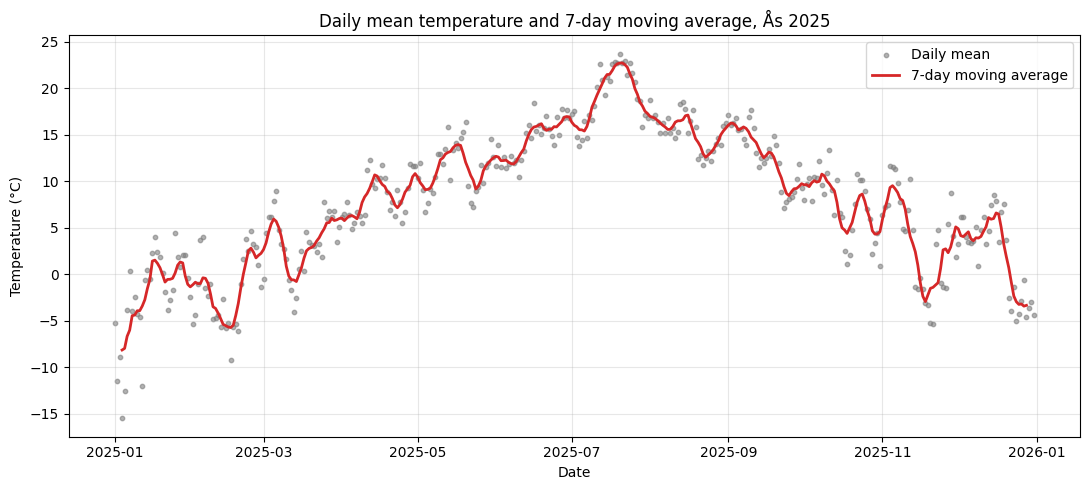

In [7]:
def moving_average(series: pd.Series, window: int = 7) -> pd.Series:
    """Centered moving average. The first and last (window // 2) days are NaN
    because there are not enough neighbouring days."""
    return series.rolling(window=window, center=True, min_periods=window).mean()


temp_ma = moving_average(temp, window=7)

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(temp.index, temp.values, s=10, color="tab:gray", alpha=0.6, label="Daily mean")
ax.plot(temp_ma.index, temp_ma.values, color="tab:red", linewidth=2, label="7-day moving average")
ax.set_title("Daily mean temperature and 7-day moving average, Ås 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### Discussion – Task 5

The moving average removes day-to-day noise and shows the seasonal trend more clearly, but it flattens short warm or cold periods and extremes. A longer window gives a smoother curve that reacts more slowly to changes.

## Summary

The temperature shows a clear seasonal cycle, precipitation is irregular, and 1925 and 2025 differ, though two years are not enough for climate conclusions. The functions `get_frost`, `count_heatwaves` and `moving_average` work for other stations and years.